# Generate Member Anomalies S2S

---

Uses the climatology generated in `2_generate_model_climatology.ipynb` to create anomalies from the S2S forecasting system.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import xarray as xr
xr.set_options(keep_attrs=True)
import cftime
import numpy as np

In [2]:
from dask_cluster import get_client
client = get_client()

Choose your model

In [3]:
model = "MPAS_60km"
zarr_dir = "output/"

In [4]:
raw = xr.open_zarr(f"{zarr_dir}{model}.raw.daily.geospatial.zarr/",consolidated=True)
clim = xr.open_zarr(f"{zarr_dir}{model}.climatology.daily.geospatial.zarr/",consolidated=True)

In [7]:
raw

<xarray.Dataset> Size: 660GB
Dimensions:  (init: 1252, member: 11, lead: 46, lat: 181, lon: 360)
Coordinates:
  * init     (init) datetime64[ns] 10kB 1999-01-04 1999-01-11 ... 2022-12-26
  * lat      (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 87.0 88.0 89.0 90.0
  * lead     (lead) int64 368B 0 1 2 3 4 5 6 7 8 ... 37 38 39 40 41 42 43 44 45
  * lon      (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * member   (member) int64 88B 1 2 3 4 5 6 7 8 9 10 11
Data variables:
    gh_500   (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    psl      (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    t2m      (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    tp       (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>

Here we want to compute the climatology before creating the anomalies so the calculation is more efficient.

In [8]:
%time clim = clim.compute()

CPU times: user 678 ms, sys: 3.6 s, total: 4.28 s
Wall time: 16.9 s


In [9]:
clim

<xarray.Dataset> Size: 18GB
Dimensions:    (dayofyear: 366, lead: 46, lat: 181, lon: 360)
Coordinates:
  * dayofyear  (dayofyear) int64 3kB 1 2 3 4 5 6 7 ... 361 362 363 364 365 366
  * lat        (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 88.0 89.0 90.0
  * lead       (lead) int64 368B 0 1 2 3 4 5 6 7 8 ... 38 39 40 41 42 43 44 45
  * lon        (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
Data variables:
    gh_500     (dayofyear, lead, lat, lon) float32 4GB 5.126e+03 ... 5.021e+03
    psl        (dayofyear, lead, lat, lon) float32 4GB 1.001e+05 ... 1.012e+05
    t2m        (dayofyear, lead, lat, lon) float32 4GB 246.5 246.5 ... 240.9
    tp         (dayofyear, lead, lat, lon) float32 4GB 3.678e-06 ... 0.3518
Attributes:
    cell_methods:  time: mean
    long_name:     Reference height temperature
    units:         K

# Calculate anomalies!

In [10]:
raw = raw.chunk({"member": -1, "init": 1, "lead": -1, "lat": 181, "lon": 360}).persist()
ds_anom = raw.groupby("init.dayofyear") - clim

In [11]:
ds_anom

<xarray.Dataset> Size: 660GB
Dimensions:    (init: 1252, lat: 181, lead: 46, lon: 360, member: 11)
Coordinates:
  * init       (init) datetime64[ns] 10kB 1999-01-04 1999-01-11 ... 2022-12-26
  * lat        (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 88.0 89.0 90.0
  * lead       (lead) int64 368B 0 1 2 3 4 5 6 7 8 ... 38 39 40 41 42 43 44 45
  * lon        (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * member     (member) int64 88B 1 2 3 4 5 6 7 8 9 10 11
    dayofyear  (init) int64 10kB 4 11 18 25 32 39 46 ... 325 332 339 346 353 360
Data variables:
    gh_500     (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    psl        (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    t2m        (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    tp         (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>

Convert the `init` dimension to a proleptic gregorian calendar using cftime.

In [12]:
ds_anom["init"] = [cftime.DatetimeProlepticGregorian(int(str(d)[0:4]), int(str(d)[5:7]), int(str(d)[8:10])) for d in ds_anom["init"].values]
encoding = {var: {"dtype": "float32"} for var in ds_anom.data_vars if np.issubdtype(ds_anom[var].dtype, np.floating)}

# Write the anomalies out to a zarr file!

In [13]:
ds_anom = ds_anom.drop_vars("dayofyear")

In [14]:
%time ds_anom.to_zarr(f"{zarr_dir}{model}.anom.daily.geospatial.zarr/",mode="w",encoding=encoding,consolidated=True)

CPU times: user 669 ms, sys: 1.81 s, total: 2.48 s
Wall time: 3min 46s


Just made a quick plot to check that they are anomalies. Looks good!

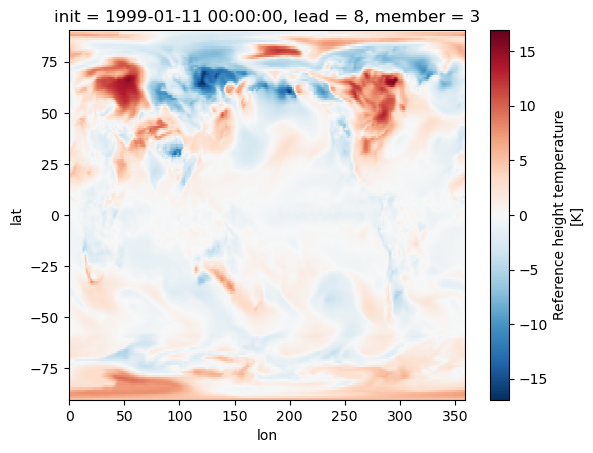

In [14]:
ds_anom.t2m.isel(init=1, lead=8, member=2).plot()